# Predicting Bitcoin Prices from Chainlet Data, Explained with SHAP

**CAP 5619, AI for Finance. Alex Hubenthal.**

This notebook predicts the daily Bitcoin price for every day of December 2017, one day ahead, from
lagged prices and chainlet features, and explains the model with SHAP. The data are the three files
provided with the course: the occurrence chainlets, the amount chainlets and the daily price.

Constraints the notebook is built around:

* Chainlet features come from both the occurrence file and the amount file.
* RMSE is computed in USD over the 31 days of December 2017.
* Dates are parsed with datetime functions and never sliced as strings. `year`, `day` and `date` are
  never model inputs.
* The horizon is one day, and nothing from December 2017 reaches training, scaling or model selection.
* Regression or feedforward networks only, no ensembles.
* SHAP explains at least three December predictions, each followed by a written reading.

## 0. Setup

The first cell checks the Python version and installs any missing package, so the notebook can start on
a machine with nothing installed. The second cell defines the constants once, so the test window and the
horizon cannot drift between cells.

In [1]:
import importlib
import importlib.util
import subprocess
import sys

MIN_PYTHON = (3, 9)
REQUIRED = {  # import name -> pip name
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "shap": "shap",
}

if sys.version_info < MIN_PYTHON:
    raise RuntimeError(
        "Python %d.%d or newer is required, found %d.%d. Install a newer Python and rerun."
        % (MIN_PYTHON + tuple(sys.version_info[:2]))
    )

missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *missing],
        capture_output=True,
        text=True,
    )
    if result.returncode != 0:
        # An "externally managed environment" error means the notebook is running in the system Python.
        raise RuntimeError(
            "pip could not install %s. If it reports an externally managed environment, run the notebook "
            "from a virtual environment (python -m venv .venv).\n%s" % (", ".join(missing), result.stderr[-1500:])
        )
    importlib.invalidate_caches()

versions = {name: importlib.import_module(name).__version__ for name in REQUIRED}
print("Python %d.%d.%d | " % tuple(sys.version_info[:3]) + ", ".join("%s %s" % item for item in versions.items()))

Python 3.13.18 | numpy 2.5.5, pandas 3.1.1, sklearn 1.9.1, matplotlib 3.11.2, shap 0.54.1


In [2]:
import os
import urllib.request

import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 12)

SEED = 5619
np.random.seed(SEED)

# The three course files are read from disk and never embedded in the notebook.
DATA_DIR = "data"
FILES = {
    "occ": "OccChainletsInTime.txt",
    "amo": "AmoChainletsInTime.txt",
    "price": "pricedBitcoin2009-2018.csv",
}
GITHUB_RAW = "https://raw.githubusercontent.com/cakcora/BitcoinChainnet/master/data/"

# The prediction task, fixed once. December 2017 is the test period; September to November 2017 is the
# validation period used for every modelling choice.
HORIZON_DAYS = 1
TEST_START = pd.Timestamp("2017-12-01")
TEST_END = pd.Timestamp("2017-12-31")
VAL_START = pd.Timestamp("2017-09-01")
VAL_END = pd.Timestamp("2017-11-30")

# The chainlet matrix is 20 x 20; row and column 20 hold the capped cells.
N_CHAINLET = 20


def ensure_data_files(data_dir=DATA_DIR):
    """Return the paths of the three course files, downloading any that are missing."""
    os.makedirs(data_dir, exist_ok=True)
    paths = {}
    for key, name in FILES.items():
        path = os.path.join(data_dir, name)
        if not os.path.exists(path):
            # Download under a temporary name so an interrupted run never leaves a half-written file.
            partial = path + ".part"
            urllib.request.urlretrieve(GITHUB_RAW + name, partial)
            os.replace(partial, path)
        paths[key] = path
        print("%-5s %s  %.1f MB" % (key, path, os.path.getsize(path) / 1e6))
    return paths


PATHS = ensure_data_files()

occ   data/OccChainletsInTime.txt  3.0 MB
amo   data/AmoChainletsInTime.txt  8.0 MB
price data/pricedBitcoin2009-2018.csv  0.1 MB


## 1. Load data and parse dates

The price file's `date` column is parsed once with `pd.to_datetime` and an explicit month/day/year
format. The chainlet files carry only `year` and `day` (the day of the year), so their dates are
assembled from those two numbers with `pd.to_datetime` and a timedelta, with no string handling. Each
loader asserts what it assumes and stops if something is off. The parsed dates are checked against
`year` and `day`, which are then dropped so they cannot reach a model by accident.

In [3]:
def load_price(path):
    """Read the price file and return a frame indexed by date with columns price and totaltx."""
    raw = pd.read_csv(path)
    assert list(raw.columns) == ["date", "price", "year", "day", "totaltx"], "unexpected price columns"

    # An explicit format avoids guessing the day/month order. The year and day checks below confirm it.
    date = pd.to_datetime(raw["date"], format="%m/%d/%Y %H:%M")
    assert date.notna().all()
    assert (date == date.dt.normalize()).all(), "price dates are not all at midnight"
    assert date.is_unique and date.is_monotonic_increasing
    assert (date.dt.year == raw["year"]).all()
    assert (date.dt.day_of_year == raw["day"]).all()
    assert (raw["price"] > 0).all()

    return raw[["price", "totaltx"]].set_index(pd.DatetimeIndex(date, name="date"))


def load_chainlets(path, prefix):
    """Read one chainlet file and return a frame indexed by date.

    Columns are `<prefix>_total` and the 400 cells `<prefix>_<i>_<o>` of the 20 x 20 chainlet matrix.
    """
    raw = pd.read_csv(path, sep="\t")
    cells = ["%d:%d" % (i, o) for i in range(1, N_CHAINLET + 1) for o in range(1, N_CHAINLET + 1)]
    assert list(raw.columns) == ["year", "day", "totaltx"] + cells, "unexpected chainlet columns"
    assert raw[cells].notna().all().all() and (raw[cells] >= 0).all().all()
    # The third column is compared with the cells instead of being trusted by its name.
    assert (raw[cells].sum(axis=1) == raw["totaltx"]).all(), "totaltx is not the sum of the cells"

    # January 1 of `year` plus (day - 1) days. A day number past the end of its year would roll into the
    # next year, which the year check catches.
    january_first = pd.to_datetime(pd.DataFrame({"year": raw["year"], "month": 1, "day": 1}))
    date = january_first + pd.to_timedelta(raw["day"] - 1, unit="D")
    assert date.is_unique and date.is_monotonic_increasing
    assert (date.dt.year == raw["year"]).all()
    assert (date.dt.day_of_year == raw["day"]).all()

    cell_frame = raw[cells].rename(columns=lambda cell: "%s_%s" % (prefix, cell.replace(":", "_")))
    # One concat instead of inserting into a 400-column frame, which pandas flags as fragmented.
    frame = pd.concat([raw["totaltx"].rename("%s_total" % prefix), cell_frame], axis=1)
    frame.index = pd.DatetimeIndex(date, name="date")
    return frame

In [4]:
price = load_price(PATHS["price"])
occ = load_chainlets(PATHS["occ"], "occ")
amo = load_chainlets(PATHS["amo"], "amo")

# December 2017 is read in full: scoring needs the actual prices, and each prediction uses the previous
# day's price.
test_days = pd.date_range(TEST_START, TEST_END, freq="D")
assert len(test_days) == 31 and test_days.isin(price.index).all()

# The days the price file lacks do exist in both chainlet files. Section 2 decides what to do with them.
price_gaps = pd.date_range(price.index.min(), price.index.max(), freq="D").difference(price.index)
assert price_gaps.isin(occ.index).all() and price_gaps.isin(amo.index).all()


def describe_source(name, frame):
    calendar = pd.date_range(frame.index.min(), frame.index.max(), freq="D")
    gaps = calendar.difference(frame.index)
    return {
        "source": name,
        "rows": len(frame),
        "first day": frame.index.min().date(),
        "last day": frame.index.max().date(),
        "index dtype": str(frame.index.dtype),
        "missing days": ", ".join(day.date().isoformat() for day in gaps) or "none",
    }


pd.DataFrame(
    [describe_source("price", price), describe_source("occurrence", occ), describe_source("amount", amo)]
).set_index("source")

,rows,first day,last day,index dtype,missing days
source,,,,,
price,2404,2011-06-01,2017-12-31,datetime64[us],"2012-12-31, 2016-12-31"
occurrence,3281,2009-01-03,2017-12-31,datetime64[us],"2009-01-04, 2009-01-05, 2009-01-06, 2009-01-07"
amount,3281,2009-01-03,2017-12-31,datetime64[us],"2009-01-04, 2009-01-05, 2009-01-06, 2009-01-07"


In [5]:
from IPython.display import display

display(price.head(3))
display(occ.iloc[:3, :4])
display(amo.iloc[:3, :4])

,price,totaltx
date,,
2011-06-01,9.57,6464
2011-06-02,10.60,7632
2011-06-03,14.29,8502


,occ_total,occ_1_1,occ_1_2,occ_1_3
date,,,,
2009-01-03,1,1,0,0
2009-01-08,14,14,0,0
2009-01-09,7,7,0,0


,amo_total,amo_1_1,amo_1_2,amo_1_3
date,,,,
2009-01-03,5000000000,5000000000,0,0
2009-01-08,70000000000,70000000000,0,0
2009-01-09,35000000000,35000000000,0,0


What the checks found, before anything is built on these frames:

* The price file runs from 2011-06-01 to 2017-12-31 (2,404 days), not from 2009 to 2018 as its name
  suggests. It lacks two calendar days, 2012-12-31 and 2016-12-31, both day 366 of a leap year, which is
  what a loop over days 1 to 365 would skip. The chainlet files do have those two days, so the merge in
  Section 2 has to decide what to do with them.
* The chainlet files run from 2009-01-03 to 2017-12-31 (3,281 days) and miss only four days at the very
  start, 2009-01-04 to 2009-01-07. Neither file reaches 2018.
* In both chainlet files the third column, `totaltx`, equals the sum of the 400 cells. In the
  occurrence file it is a transaction count. In the amount file it is a total in satoshis: the first row
  is 5,000,000,000, which is 50 bitcoin and the reward of the genesis block, where the occurrence file
  shows one transaction. The two columns share a name but not a meaning, so they are renamed `occ_total`
  and `amo_total`.
* December 2017 is complete in the price file (31 days). It is read because scoring needs the actual
  prices. It is not used for fitting, scaling or selection.

## 2. Merge occurrence, amount and price

The three frames are joined on a complete daily calendar from the first to the last price date, so every
calendar day is a row and a lag of one row is a lag of one day. Joining on the price dates alone would
skip the two missing days, and a one-row lag across such a gap would span two days.

Those two days keep their chainlet rows and get an empty price. They are not filled forward: a filled
price is an observation nobody made, and the filled day would carry a return of exactly zero. Rows that
need one of these prices, as a lag or as a target, are dropped when the model table is built in Section 3.

Nothing in this section is fitted or estimated, so keeping December 2017 in the frame does not let it
reach training.

In [6]:
def merge_sources(price, occ, amo):
    """Join the three frames on a complete daily calendar over the price period."""
    calendar = pd.date_range(price.index.min(), price.index.max(), freq="D")
    assert occ.index.equals(amo.index), "occurrence and amount files cover different days"
    assert calendar.isin(occ.index).all(), "a chainlet day is missing inside the price period"
    # Reindexing the price onto the calendar keeps its two missing days as empty rows instead of skipping them.
    return pd.concat([price["price"].reindex(calendar), occ.reindex(calendar), amo.reindex(calendar)], axis=1)


data = merge_sources(price, occ, amo)
assert data.index.is_unique and data.index.is_monotonic_increasing

# The price file's transaction count is the occurrence total under another name. Equality on every day shows
# that the three files are aligned on the same calendar date.
count_mismatches = int((price["totaltx"] != data.loc[price.index, "occ_total"]).sum())
assert count_mismatches == 0, "transaction counts disagree, so the dates do not line up"

OCC_CELLS = [name for name in data.columns if name.startswith("occ_") and name != "occ_total"]
AMO_CELLS = [name for name in data.columns if name.startswith("amo_") and name != "amo_total"]
assert len(OCC_CELLS) == len(AMO_CELLS) == N_CHAINLET ** 2

# Only the price may be empty, and only on the days the price file lacks.
assert data.drop(columns="price").notna().all().all()
assert data.index[data["price"].isna()].equals(price_gaps)

# Every score rests on the validation and test months, so they must be complete in every column.
evaluation_days = pd.date_range(VAL_START, TEST_END, freq="D")
assert data.loc[evaluation_days].notna().all().all(), "gaps in the validation or test period"

pd.Series(
    {
        "calendar days": len(data),
        "first day": data.index.min().date(),
        "last day": data.index.max().date(),
        "days with a price": int(data["price"].notna().sum()),
        "days without a price": ", ".join(day.date().isoformat() for day in price_gaps),
        "transaction count mismatches": count_mismatches,
        "occurrence cells": len(OCC_CELLS),
        "amount cells": len(AMO_CELLS),
        "columns": data.shape[1],
    },
    name="value",
).to_frame()

,value
calendar days,2406
first day,2011-06-01
last day,2017-12-31
days with a price,2404
days without a price,"2012-12-31, 2016-12-31"
transaction count mismatches,0
occurrence cells,400
amount cells,400
columns,803


In [7]:
# The gap days keep their chainlet rows and have an empty price.
around_gaps = pd.DatetimeIndex([day + pd.Timedelta(days=offset) for day in price_gaps for offset in (-1, 0, 1)])
data.loc[around_gaps, ["price", "occ_total", "amo_total"]]

,price,occ_total,amo_total
2012-12-30,13.45,43472,86628344663514
2012-12-31,NaN,27844,136824068787140
2013-01-01,13.30,35315,189995377467014
2016-12-30,960.47,288346,207216638799652
2016-12-31,NaN,224275,119964952102904
2017-01-01,997.69,204354,121705100814236


What the merge shows:

* The merged frame has 2,406 rows, one per calendar day from 2011-06-01 to 2017-12-31, and 803 columns:
  the price, the occurrence total with its 400 cells, and the amount total with its 400 cells.
* The price file's transaction count equals the occurrence total on all 2,404 days that have a price. A
  shift of even one day would break that on almost every row, so the price file and the chainlet files
  are aligned on the same calendar date, although their dates were built in two different ways.
* The only empty cells are the prices of 2012-12-31 and 2016-12-31. Both days have chainlet rows, so the
  gaps are in the price file alone.
* September to December 2017 is complete in every column.
* Chainlet history from 2009 to May 2011 is left out. A day with no price can be neither a target nor a
  lag, so that history has no use here.

## 3. Feature engineering

Each row holds what is known at the end of day t, and its target is the move from day t to day t + 1. The
prediction for December 1 therefore sits on the November 30 row, and the December 31 row has no target
because the data end there. That row is never predicted.

The target is the next-day log return, turned back into a price with the actual price on day t. A model
fitted to price levels would have to extrapolate through all of December 2017, when the price sat above
every level in the training years. A return has the same scale in every year, and the rule "tomorrow
equals today" becomes a predicted return of zero.

The features come from the price history, from both chainlet files, and from swing and momentum measures
of the price:

* Price history: seven daily log returns, return volatility over 7 and 30 days, and 30-day momentum.
* Chainlets, for the occurrence file and the amount file separately: the share of the day's total in split
  chainlets (more outputs than inputs), merge chainlets (more inputs than outputs) and the exine cells
  (row or column 20), the shares of the 1:1, 1:2 and 2:2 cells, and the log of the day's total. Shares are
  used instead of raw counts so that the long growth in activity does not dominate. Every summary is taken
  at lags 0, 1 and 2, which are the row's own day and the two days before it.
* Swing and momentum: the position inside the trailing 30 and 90 day high-low range, the distance from the
  0.618 and 0.786 retracement levels of the 90-day range, RSI(14) relative to 50, and whether RSI is
  oversold and how long ago it last was. This is the daily-data version of the levels used in harmonic
  trading.

A few candidates are left out because they are exact combinations of others: the transition share (splits,
merges and transitions add up to one), the mean transaction size (the difference of the two log totals), the
day-over-day change in each log total (a difference of two lags already in the table) and 7-day momentum
(the sum of the seven return lags). A linear model gains nothing from them, and the SHAP values in
Section 7 would divide credit arbitrarily among the features they duplicate.

Price features are built inside each unbroken run of prices, so no window crosses one of the two empty
days from Section 2 and every target is exactly one day after its row. This costs rows, because each run
needs 90 days of history before its longest window is full. The accounting is below.

In [8]:
# Feature settings, defined once so the table and the look-ahead test use the same values.
N_RET_LAGS = 7
VOL_WINDOWS = (7, 30)
MOM_WINDOW = 30
SWING_WINDOWS = (30, 90)
RSI_PERIOD = 14
OVERSOLD_LEVEL = 30
OVERSOLD_CAP = 90
CHAINLET_LAGS = (0, 1, 2)


def rsi(prices, period=RSI_PERIOD):
    """Wilder's RSI. The averages are recursive, so each value depends on past prices only."""
    change = prices.diff()
    gain = change.clip(lower=0)
    loss = -change.clip(upper=0)
    avg_gain = gain.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()
    avg_loss = loss.ewm(alpha=1 / period, adjust=False, min_periods=period).mean()
    value = 100 - 100 / (1 + avg_gain / avg_loss)
    # With no losses in the average RSI is 100 by definition, and the ratio above is undefined.
    return value.where(avg_loss > 0, 100.0).where(avg_gain.notna())


def periods_since(flag, cap):
    """Rows since the flag was last true, counted backward only and capped at `cap`."""
    position = np.arange(len(flag))
    last_true = pd.Series(np.where(flag.to_numpy(), position, np.nan), index=flag.index).ffill()
    return (position - last_true).fillna(cap).clip(upper=cap)

In [9]:
def price_block(prices):
    """Price-based features and targets for one unbroken run of consecutive daily prices."""
    log_price = np.log(prices)
    ret = log_price.diff()

    features = pd.DataFrame(index=prices.index)
    for k in range(N_RET_LAGS):
        features["ret_lag%d" % k] = ret.shift(k)
    for window in VOL_WINDOWS:
        features["vol_%d" % window] = ret.rolling(window).std()
    features["mom_%d" % MOM_WINDOW] = log_price - log_price.shift(MOM_WINDOW)

    # Position inside the trailing high-low range: 0 at the low, 1 at the high.
    for window in SWING_WINDOWS:
        high = prices.rolling(window).max()
        low = prices.rolling(window).min()
        features["swing_pos_%d" % window] = (prices - low) / (high - low).replace(0, np.nan)
    # Retracing 61.8% (78.6%) of the range puts the price at position 1 - 0.618 (1 - 0.786).
    features["dist_618_90"] = (features["swing_pos_90"] - (1 - 0.618)).abs()
    features["dist_786_90"] = (features["swing_pos_90"] - (1 - 0.786)).abs()

    strength = rsi(prices)
    known = strength.notna()
    oversold = strength < OVERSOLD_LEVEL
    features["rsi_minus_50"] = strength - 50
    features["rsi_above_50"] = (strength > 50).astype(float).where(known)
    features["oversold"] = oversold.astype(float).where(known)
    features["periods_since_oversold"] = periods_since(oversold, OVERSOLD_CAP).where(known)

    # The targets look one day forward and are never features. The last row of a run has none, because the
    # next price is either empty or past the end of the data.
    targets = pd.DataFrame(
        {
            "price": prices,
            "target_ret": ret.shift(-HORIZON_DAYS),
            "target_price": prices.shift(-HORIZON_DAYS),
        }
    )
    return features, targets


def price_side(price):
    """Run price_block on each unbroken run of prices and stack the results on the full calendar."""
    run_id = price.isna().cumsum()
    blocks = []
    for _, piece in price.groupby(run_id):
        piece = piece.dropna()
        if piece.empty:
            continue
        # Inside a run the rows are consecutive days, so a shift of k rows is a shift of k days.
        assert (piece.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all(), "a run has a missing day"
        blocks.append(price_block(piece))
    features = pd.concat([block[0] for block in blocks]).reindex(price.index)
    targets = pd.concat([block[1] for block in blocks]).reindex(price.index)
    return features, targets

In [10]:
def chainlet_groups(n=N_CHAINLET):
    """Cell names `i_o` of the split, merge and exine groups of the n x n chainlet matrix."""
    cells = [(i, o) for i in range(1, n + 1) for o in range(1, n + 1)]
    return {
        "split": ["%d_%d" % (i, o) for i, o in cells if o > i],
        "merge": ["%d_%d" % (i, o) for i, o in cells if i > o],
        "exine": ["%d_%d" % (i, o) for i, o in cells if i == n or o == n],
    }


def chainlet_features(frame, lags=CHAINLET_LAGS):
    """Daily chainlet summaries of both files, at the given lags in days."""
    groups = chainlet_groups()
    daily = {}
    for prefix in ("occ", "amo"):
        total = frame["%s_total" % prefix]
        for name, cells in groups.items():
            columns = ["%s_%s" % (prefix, cell) for cell in cells]
            daily["%s_share_%s" % (prefix, name)] = frame[columns].sum(axis=1) / total
        for cell in ("1_1", "1_2", "2_2"):
            daily["%s_share_%s" % (prefix, cell)] = frame["%s_%s" % (prefix, cell)] / total
        daily["%s_log_total" % prefix] = np.log(total)
    daily = pd.DataFrame(daily, index=frame.index)
    # The calendar has no missing day, so a shift of k rows is a lag of k days.
    return pd.concat([daily.shift(k).add_suffix("_lag%d" % k) for k in lags], axis=1)


# Split, merge and the diagonal split the 400 cells between them, which is why no transition share is built.
groups = chainlet_groups()
diagonal = ["%d_%d" % (i, i) for i in range(1, N_CHAINLET + 1)]
cell_names = {name.replace("occ_", "", 1) for name in OCC_CELLS}
parts = [set(groups["split"]), set(groups["merge"]), set(diagonal)]
assert len(groups["split"]) == len(groups["merge"]) == N_CHAINLET * (N_CHAINLET - 1) // 2
assert len(groups["exine"]) == 2 * N_CHAINLET - 1
assert sum(len(part) for part in parts) == len(cell_names) and set().union(*parts) == cell_names

In [11]:
def build_table(frame):
    """Features, targets and bookkeeping columns for every calendar day of a merged frame."""
    price_features, targets = price_side(frame["price"])
    table = pd.concat([price_features, chainlet_features(frame), targets], axis=1)
    # The day each target belongs to. It is for splitting and checking only, never a model input.
    target_date = pd.Series(table.index + pd.Timedelta(days=HORIZON_DAYS), index=table.index)
    table["target_date"] = target_date.where(table["target_ret"].notna())
    return table


assert (data[["occ_total", "amo_total"]] > 0).all().all(), "a daily total is zero, so shares are undefined"
table = build_table(data)

BOOKKEEPING = ["price", "target_ret", "target_price", "target_date"]
FEATURES = [name for name in table.columns if name not in BOOKKEEPING]
FAMILIES = {
    "price history": [c for c in FEATURES if c.startswith(("ret_", "vol_", "mom_"))],
    "swing and momentum": [
        c for c in FEATURES if c.startswith(("swing_", "dist_", "rsi_", "oversold", "periods_"))
    ],
    "occurrence chainlets": [c for c in FEATURES if c.startswith("occ_")],
    "amount chainlets": [c for c in FEATURES if c.startswith("amo_")],
}

# Every feature sits in exactly one family, and none is a date, a year, a day or anything of the target.
# The check is on name fragments, so a name such as "days_since" would be caught as well.
assert sum(len(cols) for cols in FAMILIES.values()) == len(FEATURES) == len(set(FEATURES))
assert not [c for c in FEATURES if any(token in c for token in ("year", "day", "date", "target"))]
assert not set(FEATURES) & set(BOOKKEEPING)
# Both chainlet files feed the model.
assert FAMILIES["occurrence chainlets"] and FAMILIES["amount chainlets"]

pd.DataFrame(
    {
        "features": {name: len(cols) for name, cols in FAMILIES.items()},
        "examples": {name: ", ".join(cols[:2]) for name, cols in FAMILIES.items()},
    }
)

,features,examples
price history,10,"ret_lag0, ret_lag1"
swing and momentum,8,"swing_pos_30, swing_pos_90"
occurrence chainlets,21,"occ_share_split_lag0, occ_share_merge_lag0"
amount chainlets,21,"amo_share_split_lag0, amo_share_merge_lag0"


In [12]:
has_target = table["target_ret"].notna()
target_dates = pd.DatetimeIndex(table.loc[has_target, "target_date"])

# The target must be the price file's value on the next calendar day, looked up by date and not by position.
assert (target_dates - table.index[has_target] == pd.Timedelta(days=HORIZON_DAYS)).all()
looked_up = data["price"].reindex(target_dates).to_numpy()
assert np.array_equal(looked_up, table.loc[has_target, "target_price"].to_numpy())
log_move = np.log(table.loc[has_target, "target_price"] / table.loc[has_target, "price"])
assert np.allclose(table.loc[has_target, "target_ret"], log_move)

# The last day of November carries the first day of December as its target, and the last day of the data
# carries none.
alignment_days = pd.DatetimeIndex([VAL_END, TEST_START, TEST_END - pd.Timedelta(days=1), TEST_END])
table.loc[alignment_days, ["price", "target_price", "target_ret", "target_date"]]

,price,target_price,target_ret,target_date
2017-11-30,10147.372,10883.91200,0.070071,2017-12-01
2017-12-01,10883.912,11071.36833,0.017077,2017-12-02
2017-12-30,13215.574,14165.57500,0.069419,2017-12-31
2017-12-31,14165.575,NaN,NaN,NaT


In [13]:
no_price = table["price"].isna()
no_target = ~no_price & table["target_ret"].isna()
warm_up = ~no_price & ~no_target & table[FEATURES].isna().any(axis=1)
complete = ~(no_price | no_target | warm_up)

in_validation = table["target_date"].between(VAL_START, VAL_END)
in_test = table["target_date"].between(TEST_START, TEST_END)
# Every validation day and every December day must have a complete row to be predicted from.
assert in_validation.sum() == complete[in_validation].sum() == 91
assert in_test.sum() == complete[in_test].sum() == 31

# Intermediate results are checked against what they have to look like.
usable = table.loc[complete, FEATURES]
assert np.isfinite(usable.to_numpy()).all()
unit_interval = usable[[c for c in FEATURES if "_share_" in c or c.startswith("swing_pos")]]
assert ((unit_interval >= 0) & (unit_interval <= 1)).all().all()
assert usable["rsi_minus_50"].abs().max() <= 50

# No feature may be an exact combination of the others. Only rows before the validation window are used.
fit_rows = table.loc[complete & (table["target_date"] < VAL_START), FEATURES]
standardized = (fit_rows - fit_rows.mean()) / fit_rows.std()
assert np.linalg.matrix_rank(standardized.to_numpy()) == len(FEATURES)

pd.Series(
    {
        "calendar days": len(table),
        "no price that day": int(no_price.sum()),
        "no price the next day (end of a run)": int(no_target.sum()),
        "windows not yet full (start of a run)": int(warm_up.sum()),
        "complete rows": int(complete.sum()),
        "complete, target before September 2017": int((complete & (table["target_date"] < VAL_START)).sum()),
        "complete, target in the validation window": int(complete[in_validation].sum()),
        "complete, target in December 2017": int(complete[in_test].sum()),
    },
    name="rows",
).to_frame()

,rows
calendar days,2406
no price that day,2
no price the next day (end of a run),3
windows not yet full (start of a run),267
complete rows,2134
"complete, target before September 2017",2012
"complete, target in the validation window",91
"complete, target in December 2017",31


### Proof that no feature looks ahead

Reading the feature code is not enough, so the test breaks the future and checks whether the past notices.
For each cutoff date the features are rebuilt twice. First from data that stop at the cutoff, then from
data in which every value after the cutoff is multiplied by random noise. A centered window, a forward
shift or a statistic taken over the whole sample would change a feature on or before the cutoff, and the
comparison would fail.

In [14]:
def assert_no_lookahead(frame, cutoff, trials=2):
    """Change everything after `cutoff`, rebuild the features and require that nothing up to it moves."""
    clean = frame.astype("float64")
    reference = build_table(clean)
    upto = reference.index <= cutoff
    expected = reference.loc[upto, FEATURES]

    # Truncation: the features up to the cutoff must not need any later day to exist.
    truncated = build_table(clean.loc[clean.index <= cutoff])
    pd.testing.assert_frame_equal(truncated[FEATURES], expected, check_freq=False)

    # Corruption: later values are scaled by random factors, which breaks any hidden use of the future.
    rng = np.random.default_rng(SEED)
    later = ~upto
    for _ in range(trials):
        noisy = clean.copy()
        factors = rng.uniform(0.5, 2.0, size=(int(later.sum()), clean.shape[1]))
        noisy.loc[later, :] = clean.loc[later, :].to_numpy() * factors
        pd.testing.assert_frame_equal(build_table(noisy).loc[upto, FEATURES], expected, check_freq=False)
    return {
        "cutoff": cutoff.date(),
        "rows compared": int(upto.sum()),
        "truncated rebuild": "unchanged",
        "corrupted futures": trials,
        "after corruption": "unchanged",
    }


cutoffs = [pd.Timestamp("2014-06-30"), pd.Timestamp("2017-06-30"), VAL_END, pd.Timestamp("2017-12-15")]
pd.DataFrame([assert_no_lookahead(data, cutoff) for cutoff in cutoffs]).set_index("cutoff")

,rows compared,truncated rebuild,corrupted futures,after corruption
cutoff,,,,
2014-06-30,1126,unchanged,2,unchanged
2017-06-30,2222,unchanged,2,unchanged
2017-11-30,2375,unchanged,2,unchanged
2017-12-15,2390,unchanged,2,unchanged


What the feature table shows:

* There are 60 features: 10 from the price history, 8 swing and momentum measures, and 21 from each
  chainlet file. No feature name carries a date, a year or a day, and none is an exact combination of the
  others, since the standardized features have full rank on the rows before September 2017.
* 2,134 of the 2,406 calendar days have a complete row. The two empty prices cost 182 of the lost rows: the
  two empty days, the two days before them (no next-day price), and the first 89 rows of each run that
  follows. The other 90 are the start of the data and the last day.
* All 91 validation days and all 31 December days have a complete row, and the November 30 row carries the
  December 1 price as its target.
* The look-ahead test passes at four cutoffs, from mid-2014 to the middle of December 2017.
* Neighboring lags of the same chainlet summary are strongly correlated, 0.99 for the log totals. That is
  normal for daily series and not an exact overlap, but a signal in one summary will show up spread over
  its three lags when Section 7 reads the SHAP values.

## 4. Split and scaling

Time runs one way, so the split is chronological and nothing is shuffled or cross-validated. Rows are
assigned by the date of their target, the day being predicted:

* Fitting pool: targets before September 1, 2017.
* Validation: targets from September 1 to November 30, 2017, 91 predictions. Every modeling choice is made
  here: the training window, the ridge penalty and the feature set.
* Test: targets from December 1 to 31, 2017, 31 predictions, scored once at the end.

Predictions come from a walk-forward loop. To predict day D, the loop takes the row of day D - 1 as its
input and fits on the most recent W calendar days of rows whose targets were already known at the end of
day D - 1. The scaler is fitted on those same rows inside the loop, so no mean or spread from a later day
can reach it. The model is refit every day, which uses the freshest information and still predicts one day
ahead. The same function can also freeze one model at the start of the month, which is the other way to
read "predict December".

December is locked. The loop refuses a target day after November 30 unless it is called with
`allow_test=True`, which only the leak check below and the final evaluation do.

In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler


def rmse(y, y_):
    """Root mean squared error in dollars, with `y` the actual prices and `y_` the predicted prices."""
    y, y_ = np.asarray(y, dtype=float), np.asarray(y_, dtype=float)
    assert y.ndim == 1 and y.shape == y_.flatten().shape, "one actual and one predicted price per day"
    return np.sqrt(((y - y_.flatten()) ** 2).mean())


def usable_rows(table):
    """Rows with every feature and a target. All candidate models are fitted on the same rows."""
    return table[FEATURES + ["target_ret"]].notna().all(axis=1)


usable = usable_rows(table)
assert usable.equals(complete)
splits = {
    "fitting pool": usable & (table["target_date"] < VAL_START),
    "validation": usable & table["target_date"].between(VAL_START, VAL_END),
    "test": usable & table["target_date"].between(TEST_START, TEST_END),
}

# The sets do not overlap and follow each other in time.
first_day = {name: table.loc[rows, "target_date"].min() for name, rows in splits.items()}
last_day = {name: table.loc[rows, "target_date"].max() for name, rows in splits.items()}
assert not (splits["fitting pool"] & splits["validation"]).any()
assert not (splits["validation"] & splits["test"]).any()
assert last_day["fitting pool"] < first_day["validation"] and last_day["validation"] < first_day["test"]

pd.DataFrame(
    {
        "first target day": {name: day.date() for name, day in first_day.items()},
        "last target day": {name: day.date() for name, day in last_day.items()},
        "rows": {name: int(rows.sum()) for name, rows in splits.items()},
    }
)

,first target day,last target day,rows
fitting pool,2011-08-30,2017-08-31,2012
validation,2017-09-01,2017-11-30,91
test,2017-12-01,2017-12-31,31


In [16]:
def walk_forward(
    table,
    features,
    make_model,
    window_days,
    first_target,
    last_target,
    refit_every=1,
    allow_test=False,
    keep_fits=False,
):
    """Predict each day from `first_target` to `last_target`, one day ahead.

    The prediction for day D takes the row of day D - 1 as its input. The scaler and the model are fitted on
    the rows whose targets were already known at the end of day D - 1, limited to the most recent
    `window_days` days, and refit every `refit_every` days: 1 is a daily refit, and the length of the range is
    one model frozen at the start. `make_model` returns an unfitted regressor.

    With `keep_fits=True` the function returns the predictions and a dictionary with the scaler, the model and
    the days of the training rows behind each prediction, so a prediction can be explained with the very fit
    that made it. The predictions themselves do not depend on this switch.
    """
    if not allow_test:
        assert last_target <= VAL_END, "the test month is predicted only by the final evaluation"
    usable = usable_rows(table).to_numpy()
    target_date = table["target_date"]
    inputs = table[features].to_numpy()
    moves = table["target_ret"].to_numpy()
    prices = table["price"].to_numpy()
    answers = table["target_price"].to_numpy()

    records, fits = [], {}
    for step, day in enumerate(pd.date_range(first_target, last_target, freq="D")):
        today = day - pd.Timedelta(days=HORIZON_DAYS)
        if step % refit_every == 0:
            # A row's target is known once its target date has passed, and the window looks back from today.
            known = usable & (target_date <= today).to_numpy()
            known &= (target_date > today - pd.Timedelta(days=window_days)).to_numpy()
            scaler = StandardScaler().fit(inputs[known])
            model = make_model().fit(scaler.transform(inputs[known]), moves[known])
            fit_info = {
                "fitted_on": today,
                "train_rows": int(known.sum()),
                "train_first_target": target_date[known].min(),
                "train_last_target": target_date[known].max(),
            }
            fit = {"scaler": scaler, "model": model, "train_days": table.index[known]}
        fits[day] = fit
        position = table.index.get_loc(today)
        row = scaler.transform(inputs[position : position + 1])
        assert np.isfinite(row).all(), "the input row is incomplete"
        predicted_return = float(model.predict(row)[0])
        records.append(
            {
                "target_day": day,
                "actual": answers[position],
                "predicted": prices[position] * np.exp(predicted_return),
                "predicted_return": predicted_return,
                "previous_price": prices[position],
                **fit_info,
            }
        )
    result = pd.DataFrame(records).set_index("target_day")
    assert (result["train_last_target"] < result.index.to_series()).all(), "a fit saw its own target day"
    return (result, fits) if keep_fits else result

In [17]:
# Placeholders for the checks in this section only. Section 5 chooses the window and the penalty on validation.
CHECK_WINDOW_DAYS = 730
CHECK_ALPHA = 100.0


def make_naive():
    """The rule "tomorrow equals today", which is a predicted return of zero."""
    return DummyRegressor(strategy="constant", constant=0.0)


def make_ridge():
    return Ridge(alpha=CHECK_ALPHA)


# The loop is checked against the price file with the naive rule, whose predicted price is today's price.
validation_days = pd.date_range(VAL_START, VAL_END, freq="D")
naive = walk_forward(table, FEATURES, make_naive, CHECK_WINDOW_DAYS, VAL_START, VAL_END)
tomorrow = data["price"].reindex(validation_days).to_numpy()
today_price = data["price"].reindex(validation_days - pd.Timedelta(days=HORIZON_DAYS)).to_numpy()
assert np.array_equal(naive["actual"].to_numpy(), tomorrow)
assert np.allclose(naive["predicted"].to_numpy(), today_price)
NAIVE_VALIDATION_RMSE = rmse(naive["actual"], naive["predicted"])
assert np.isclose(NAIVE_VALIDATION_RMSE, rmse(tomorrow, today_price))

pd.Series(
    {
        "validation RMSE, tomorrow equals today (USD)": round(NAIVE_VALIDATION_RMSE, 1),
        "rows in the smallest fit": int(naive["train_rows"].min()),
        "rows in the largest fit": int(naive["train_rows"].max()),
    },
    name="value",
    dtype=object,
).to_frame()

,value
"validation RMSE, tomorrow equals today (USD)",266.1
rows in the smallest fit,639
rows in the largest fit,639


In [18]:
# What the loop used, for the first validation day and the first and last December days.
audit_days = [VAL_START, TEST_START, TEST_END]
used = pd.concat(
    [walk_forward(table, FEATURES, make_ridge, CHECK_WINDOW_DAYS, day, day, allow_test=True) for day in audit_days]
)
used[["fitted_on", "train_rows", "train_first_target", "train_last_target"]]

,fitted_on,train_rows,train_first_target,train_last_target
target_day,,,,
2017-09-01,2017-08-31,639,2015-09-02,2017-08-31
2017-12-01,2017-11-30,639,2015-12-02,2017-11-30
2017-12-31,2017-12-30,639,2016-01-01,2017-12-30


### Proof that nothing after the prediction day reaches the fit

The check poisons the future. For each prediction day, everything the model could not have known at the end
of the day before is replaced by random noise: the answer itself, which is the target of the day-before row,
and every value of the later rows. The prediction is recomputed and has to come out identical. A scaler
fitted on the whole table, a training window that takes in the day-before row with its own target, or an
input row taken one day too late would each change the prediction. The check covers every day of the
validation window and of December, with a daily refit and with one model frozen on November 30. It uses a
ridge model, so that the fit really depends on its training rows.

In [19]:
def poison_future(table, today):
    """Copy of the table with everything not known at the end of `today` replaced by noise.

    That is the target of the `today` row, which is the answer being predicted, and every value of the later
    rows. Noise goes only where a value exists, so the set of usable rows does not change.
    """
    columns = FEATURES + ["price", "target_ret", "target_price"]
    values = table[columns].to_numpy(dtype=float)
    later = np.asarray(table.index > today)
    same_day = np.asarray(table.index == today)
    is_target = np.array([name.startswith("target_") for name in columns])
    unknown = later[:, None] | (same_day[:, None] & is_target[None, :])
    unknown &= ~np.isnan(values)

    noise = np.random.default_rng(SEED).normal(scale=100.0, size=values.shape)
    poisoned = table.copy()
    poisoned[columns] = np.where(unknown, noise, values)
    return poisoned


def assert_no_leak(table, scenarios, make_model, window_days):
    """Poison the unknown future for every day of every scenario and require identical predictions."""
    results = []
    for label, first, last, refit_every in scenarios:
        days = pd.date_range(first, last, freq="D")
        largest = 0.0
        for day in days:
            # A daily refit can be tested one day at a time. A frozen model is tested from the start of its range.
            settings = {
                "first_target": day if refit_every == 1 else first,
                "last_target": day,
                "refit_every": refit_every,
                "allow_test": True,
            }
            clean = walk_forward(table, FEATURES, make_model, window_days, **settings)
            poisoned = poison_future(table, day - pd.Timedelta(days=HORIZON_DAYS))
            noisy = walk_forward(poisoned, FEATURES, make_model, window_days, **settings)
            largest = max(largest, abs(clean.loc[day, "predicted"] - noisy.loc[day, "predicted"]))
        assert largest < 1e-6, "%s: a prediction moved when the future was replaced by noise" % label
        results.append({"scenario": label, "days checked": len(days), "largest change (USD)": largest})
    return pd.DataFrame(results).set_index("scenario")


scenarios = [
    ("validation, daily refit", VAL_START, VAL_END, 1),
    ("December, daily refit", TEST_START, TEST_END, 1),
    ("December, one model frozen on November 30", TEST_START, TEST_END, len(test_days)),
]
assert_no_leak(table, scenarios, make_ridge, CHECK_WINDOW_DAYS)

,days checked,largest change (USD)
scenario,,
"validation, daily refit",91,0.0
"December, daily refit",31,0.0
"December, one model frozen on November 30",31,0.0


### Findings

* The 2,134 usable rows split into 2,012 for fitting (targets through August 31), 91 for validation and 31
  for the test month. The three sets do not overlap and each ends before the next one starts.
* Run through the loop, the rule "tomorrow equals today" reproduces the prices in the file exactly and scores a
  validation RMSE of 266.1 dollars. That is the number a model has to beat in Section 5.
* Windows are counted in calendar days, and a 730-day window holds 639 rows, not 730. The 91 target days from
  December 31, 2016 to March 31, 2017 have no complete row: the missing price on December 31 ends one run of
  prices, and the next run needs its 89-day warm-up before its features exist. Every validation and December
  day sees the same 639 rows with this window, so window sizes in Section 5 are days of history, not row counts.
* Every fit stops at the day before its prediction. Even for a ridge model, whose fit depends on its training
  rows, replacing everything after that day with noise changes no prediction. December predictions were made
  here only for this check, and no December error was computed.

## 5. Model selection

The model is a ridge regression on the 60 features that predicts the next day's log return. Two settings are
open: how many days of history each fit uses, the window, and how strongly ridge shrinks the weights, the
penalty `alpha`. Both are chosen here by walking forward through the validation months with the loop from
Section 4 and scoring the predicted prices in dollars. The largest window, 10,000 days, simply means all of the
history. The feature set is not tuned. The task needs chainlet features from both files, and 91 days are too
few to drop a family on their say-so. A table of what each family adds comes after the choice and plays no part
in it.

Two baselines say what a model has to beat. "Tomorrow equals today" predicts a return of zero. The drift
baseline predicts the average daily return of the window, so it shows whether the features add anything beyond
the trend of the period. The test month is not touched in this section: every run stops at November 30 and the
December lock from Section 4 stays on.

In [20]:
from functools import partial

ALL_HISTORY = 10_000  # days, longer than the data
WINDOWS = [120, 180, 270, 365, 545, 730, 1095, ALL_HISTORY]
ALPHAS = [3, 10, 30, 100, 300, 1000, 3000, 10_000]


def validation_run(make_model, window_days, features=FEATURES):
    """One walk-forward pass over the validation months, with the December lock on."""
    run = walk_forward(table, features, make_model, window_days, VAL_START, VAL_END)
    assert run.index.equals(pd.date_range(VAL_START, VAL_END, freq="D"))
    return run


def score(run):
    return rmse(run["actual"], run["predicted"])


def make_drift():
    """The average daily return of the window, whatever the features say."""
    return DummyRegressor(strategy="mean")


records = []
for window_days in WINDOWS:
    for alpha in ALPHAS:
        run = validation_run(partial(Ridge, alpha=alpha), window_days)
        records.append(
            {
                "window_days": window_days,
                "alpha": alpha,
                "rmse": score(run),
                "rows_fewest": run["train_rows"].min(),
                "rows_most": run["train_rows"].max(),
            }
        )
grid = pd.DataFrame(records)
drift = pd.Series({window_days: score(validation_run(make_drift, window_days)) for window_days in WINDOWS})

# Validation RMSE in dollars. Rows are windows, columns are penalties.
rows_per_fit = grid.groupby("window_days").agg(low=("rows_fewest", "min"), high=("rows_most", "max"))
surface = grid.pivot(index="window_days", columns="alpha", values="rmse").round(1)
fit_sizes = [
    "%d" % low if low == high else "%d to %d" % (low, high)
    for low, high in zip(rows_per_fit["low"], rows_per_fit["high"])
]
surface.insert(0, "rows per fit", fit_sizes)
surface["drift baseline"] = drift.round(1)
print("tomorrow equals today: %.1f" % NAIVE_VALIDATION_RMSE)
surface

tomorrow equals today: 266.1


alpha,rows per fit,3,10,30,100,300,1000,3000,10000,drift baseline
window_days,,,,,,,,,,
120,120,342.8,302.0,272.8,258.8,257.3,258.4,258.6,258.4,258.2
180,153 to 180,311.7,297.1,278.3,262.2,257.1,257.7,258.7,259.0,259.0
270,179 to 243,291.4,281.1,268.5,257.8,254.8,256.1,257.5,258.1,258.3
365,274,278.0,270.7,261.4,253.4,252.2,255.0,257.0,257.6,257.7
545,454,262.2,259.6,257.0,254.6,253.8,255.2,257.1,258.4,259.3
730,639,251.4,250.6,250.1,250.3,251.5,254.1,256.6,258.5,260.3
1095,1004,255.5,254.7,253.8,253.1,253.1,254.7,256.9,259.1,262.1
10000,2012 to 2102,258.6,258.1,257.7,257.4,257.5,258.0,258.6,259.6,263.0


The choice is the window and penalty with the lowest validation RMSE. The five best are listed so the
neighborhood of the winner is visible: a sharp minimum that its neighbors do not share would be luck.

In [21]:
ranked = grid.sort_values("rmse").reset_index(drop=True)
best = ranked.iloc[0]
WINDOW_DAYS, ALPHA = int(best["window_days"]), float(best["alpha"])


def make_final():
    return Ridge(alpha=ALPHA)


ranked.head(5).round(1)

,window_days,alpha,rmse,rows_fewest,rows_most
0,730,30,250.1,639,639
1,730,100,250.3,639,639
2,730,10,250.6,639,639
3,730,3,251.4,639,639
4,730,300,251.5,639,639


### The chosen model against the baselines

The same walk-forward run month by month, and the number of days on which the chosen model's error is smaller
than the error of "tomorrow equals today".

In [22]:
runs = {
    "ridge, chosen": validation_run(make_final, WINDOW_DAYS),
    "tomorrow equals today": validation_run(make_naive, WINDOW_DAYS),
    "drift": validation_run(make_drift, WINDOW_DAYS),
}
assert np.isclose(score(runs["ridge, chosen"]), best["rmse"])
assert np.isclose(score(runs["tomorrow equals today"]), NAIVE_VALIDATION_RMSE)

by_month = pd.DataFrame(
    {
        name: {start.date(): score(part) for start, part in run.groupby(pd.Grouper(freq="MS"))}
        for name, run in runs.items()
    }
)
by_month.loc["all validation"] = [score(run) for run in runs.values()]

abs_error = {name: (run["actual"] - run["predicted"]).abs() for name, run in runs.items()}
wins = int((abs_error["ridge, chosen"] < abs_error["tomorrow equals today"]).sum())
print("days with a smaller error than tomorrow equals today: %d of %d" % (wins, len(runs["ridge, chosen"])))
by_month.round(1)

days with a smaller error than tomorrow equals today: 50 of 91


,"ridge, chosen",tomorrow equals today,drift
2017-09-01,222.1,225.9,228.5
2017-10-01,186.6,183.9,177.1
2017-11-01,323.2,358.9,347.8
all validation,250.1,266.1,260.3


### What each feature family adds

The chosen window and penalty again, with fewer feature families. This describes the chosen model and is not a
selection step: the model keeps all four families. Every row uses the penalty chosen above, so the smaller sets
are not tuned for themselves.

In [23]:
family_sets = {
    "price history": ["price history"],
    "price history, swing": ["price history", "swing and momentum"],
    "price history, swing, occurrence": ["price history", "swing and momentum", "occurrence chainlets"],
    "price history, swing, amount": ["price history", "swing and momentum", "amount chainlets"],
    "all four (the model)": list(FAMILIES),
}


def columns_of(names):
    return [column for name in names for column in FAMILIES[name]]


ablation = pd.DataFrame(
    {
        "features": {label: len(columns_of(names)) for label, names in family_sets.items()},
        "validation RMSE": {
            label: score(validation_run(make_final, WINDOW_DAYS, columns_of(names)))
            for label, names in family_sets.items()
        },
    }
)
assert np.isclose(ablation.loc["all four (the model)", "validation RMSE"], best["rmse"])
ablation.round(1)

,features,validation RMSE
price history,10,261.9
"price history, swing",18,257.7
"price history, swing, occurrence",39,259.7
"price history, swing, amount",39,249.4
all four (the model),60,250.1


### Leak check with the chosen settings

The check from Section 4 again, with the chosen window and penalty, over the validation months. December is
checked in Section 6, next to its predictions.

In [24]:
assert_no_leak(table, scenarios[:1], make_final, WINDOW_DAYS)

,days checked,largest change (USD)
scenario,,
"validation, daily refit",91,0.0


### Findings

* The choice is a 730-day window and a penalty of 30, with a validation RMSE of 250.1 dollars. It is the best of
  64 settings on the same 91 days, so it is a little optimistic, and the December score in Section 6 is the only
  unbiased figure. The window holds 639 rows, not 730, because of the stretch of early 2017 with no complete row.
* The minimum is shallow. The winner is inside the grid on both axes. The five best settings all use the
  730-day window with penalties from 3 to 300 (250.1 to 251.5), and the best penalty of every other window from
  270 to 1,095 days lands within 2 percent of the winner (252.2 to 254.8). The exact pick is a mild preference,
  not a finding.
* Against the baselines the gain is real but small. "Tomorrow equals today" scores 266.1 and the drift baseline
  257.7 at its best window, so a bit over half of the model's gain comes from the average return alone, which
  only helps while prices keep rising. The model's error is smaller than the naive error on 50 of 91 days. By
  month it wins in September (222.1 against 225.9) and in November (323.2 against 358.9) and loses in October
  (186.6 against 183.9), so most of the gain comes from November.
* The gain beyond price history comes from the amount chainlets. Price history alone scores 261.9 and the swing
  features bring it to 257.7. Adding the amount chainlets gives 249.4, while adding the occurrence chainlets
  instead gives 259.7. With both files the model scores 250.1. Both files stay in, as the task requires, and
  leaving the occurrence features out would move the score by less than a dollar.
* With the chosen settings, replacing everything after the day before with noise moves no validation prediction.

## 6. Final evaluation on December 2017

Every setting comes from Section 5: ridge on the 60 features, a 730-day window and a penalty of 30. This is
the first time the test month is scored, and it is scored once. Nothing below changes a setting and nothing
after this section does either.

The primary result refits the model every day, so the prediction for day D uses everything known at the end of
day D - 1, the earlier days of December included. The second reading of "test data is December" freezes one
model on November 30 and applies it to all 31 days. The two baselines from Section 5 are scored the same way,
for context. None of these models is tuned on December.

### Leak check before scoring

The check from Sections 4 and 5, now with the chosen settings and all three scenarios: the validation months,
December with a daily refit, and December with one model frozen on November 30. For every target day,
everything unknown at the end of the day before is replaced by noise, and the prediction must not move. The
check compares predictions with each other and never with prices. It runs first, so a leak would stop the
notebook before any December score exists.

In [25]:
assert_no_leak(table, scenarios, make_final, WINDOW_DAYS)

,days checked,largest change (USD)
scenario,,
"validation, daily refit",91,0.0
"December, daily refit",31,0.0
"December, one model frozen on November 30",31,0.0


### Scoring

One run per model over the 31 days of December. The RMSE is in dollars, computed with `rmse` from Section 4 on
the actual and the predicted prices.

In [26]:
december_run = walk_forward(table, FEATURES, make_final, WINDOW_DAYS, TEST_START, TEST_END, allow_test=True)
frozen_run = walk_forward(
    table, FEATURES, make_final, WINDOW_DAYS, TEST_START, TEST_END, refit_every=len(test_days), allow_test=True
)
naive_december = walk_forward(table, FEATURES, make_naive, WINDOW_DAYS, TEST_START, TEST_END, allow_test=True)
drift_december = walk_forward(table, FEATURES, make_drift, WINDOW_DAYS, TEST_START, TEST_END, allow_test=True)

december_runs = {
    "ridge, refit daily": december_run,
    "ridge, frozen on Nov 30": frozen_run,
    "tomorrow equals today": naive_december,
    "drift": drift_december,
}

# y holds the 31 actual prices, and every run is checked against it and against the 31 days.
y = data["price"].reindex(test_days).to_numpy()
assert len(y) == 31
for run in december_runs.values():
    assert run.index.equals(test_days) and np.array_equal(run["actual"].to_numpy(), y)

BASELINE = "tomorrow equals today"
abs_error = {name: (run["actual"] - run["predicted"]).abs() for name, run in december_runs.items()}


def direction_hits(run):
    """Days on which the predicted move from the previous day has the same sign as the actual move."""
    predicted_move = np.sign(run["predicted"] - run["previous_price"])
    return int((predicted_move == np.sign(run["actual"] - run["previous_price"])).sum())


scores = {}
for name, run in december_runs.items():
    has_baseline = name != BASELINE
    scores[name] = {
        "RMSE (USD)": round(rmse(y, run["predicted"]), 1),
        "days better than naive": int((abs_error[name] < abs_error[BASELINE]).sum()) if has_baseline else "-",
        "days with the right direction": direction_hits(run) if has_baseline else "-",
    }
pd.DataFrame.from_dict(scores, orient="index")

,RMSE (USD),days better than naive,days with the right direction
"ridge, refit daily",1183.4,11,12
"ridge, frozen on Nov 30",1200.7,11,12
tomorrow equals today,1095.1,-,-
drift,1094.5,16,17


"Naive" is the rule that tomorrow equals today. A day is better than naive when the model's absolute error is
smaller than the naive error on that day, and the direction is right when the predicted move from the previous
day has the sign of the actual move.

The 31 predictions of the primary run, with the naive rule beside them:

In [27]:
daily = pd.DataFrame(
    {
        "actual": december_run["actual"],
        "predicted": december_run["predicted"],
        "error": december_run["predicted"] - december_run["actual"],
        "naive": naive_december["predicted"],
    }
)
squared_error = daily["error"] ** 2
worst_days = squared_error.sort_values(ascending=False).head(5).index.sort_values()
worst_labels = ", ".join(str(day.day) for day in worst_days)
print("worst five days of the primary run, by day of the month: %s" % worst_labels)
print(
    "they carry %.0f%% of its squared error; their mean absolute error is %.0f for the model and %.0f for naive"
    % (
        100 * squared_error[worst_days].sum() / squared_error.sum(),
        abs_error["ridge, refit daily"][worst_days].mean(),
        abs_error[BASELINE][worst_days].mean(),
    )
)
daily.round(2)

worst five days of the primary run, by day of the month: 6, 7, 11, 20, 26
they carry 56% of its squared error; their mean absolute error is 2145 for the model and 2021 for naive


,actual,predicted,error,naive
target_day,,,,
2017-12-01,10883.91,10268.57,-615.34,10147.37
2017-12-02,11071.37,10963.50,-107.87,10883.91
2017-12-03,11332.62,11061.48,-271.14,11071.37
2017-12-04,11584.83,11564.04,-20.79,11332.62
2017-12-05,11878.43,11608.96,-269.47,11584.83
2017-12-06,13540.98,11837.72,-1703.26,11878.43
2017-12-07,16501.97,13430.27,-3071.70,13540.98
2017-12-08,16007.44,16559.57,552.14,16501.97
2017-12-09,15142.83,16557.36,1414.52,16007.44


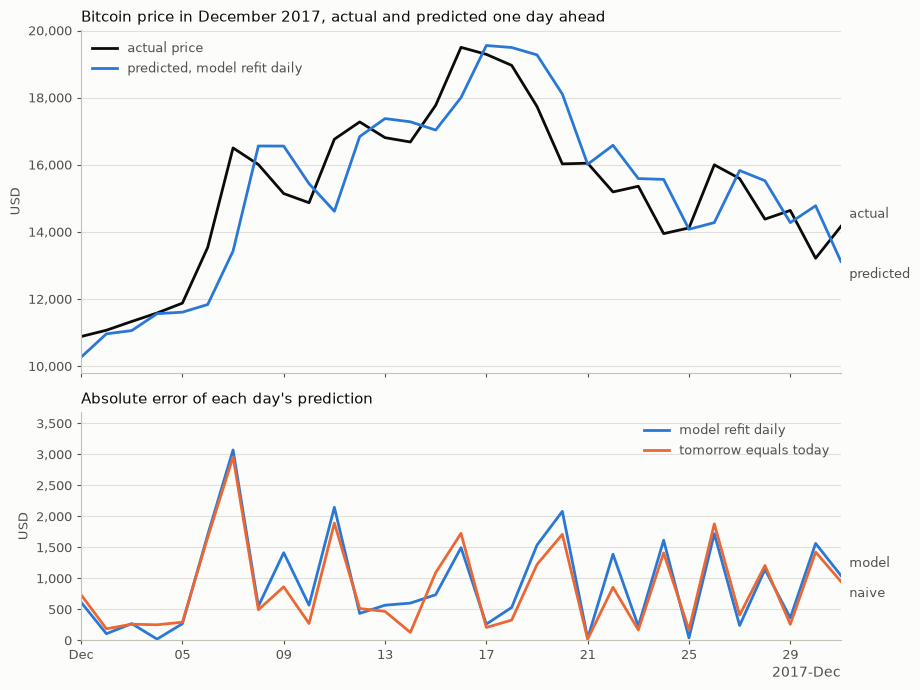

In [28]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Neutral ink for the actual price, and slots 1 and 2 of a validated categorical palette for the two predictors.
SURFACE, INK, SECONDARY, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"


def style_axes(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=SECONDARY, labelsize=9, length=3)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_ylabel("USD", color=SECONDARY, fontsize=9)


def label_end(ax, day, value, text, above):
    ax.annotate(
        text,
        xy=(day, value),
        xytext=(6, 4 if above else -4),
        textcoords="offset points",
        va="bottom" if above else "top",
        color=SECONDARY,
        fontsize=9,
        annotation_clip=False,
    )


days = december_run.index
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, facecolor=SURFACE, height_ratios=[3, 2])

top.plot(days, december_run["actual"], color=INK, linewidth=2, label="actual price")
top.plot(days, december_run["predicted"], color=BLUE, linewidth=2, label="predicted, model refit daily")
actual_last, predicted_last = december_run["actual"].iloc[-1], december_run["predicted"].iloc[-1]
label_end(top, days[-1], actual_last, "actual", actual_last >= predicted_last)
label_end(top, days[-1], predicted_last, "predicted", actual_last < predicted_last)
style_axes(top, "Bitcoin price in December 2017, actual and predicted one day ahead")

model_error, naive_error = abs_error["ridge, refit daily"], abs_error[BASELINE]
bottom.plot(days, model_error, color=BLUE, linewidth=2, label="model refit daily")
bottom.plot(days, naive_error, color=ORANGE, linewidth=2, label=BASELINE)
label_end(bottom, days[-1], model_error.iloc[-1], "model", model_error.iloc[-1] >= naive_error.iloc[-1])
label_end(bottom, days[-1], naive_error.iloc[-1], "naive", naive_error.iloc[-1] > model_error.iloc[-1])
style_axes(bottom, "Absolute error of each day's prediction")

top.legend(loc="upper left", frameon=False, fontsize=9, labelcolor=SECONDARY)
bottom.legend(loc="upper right", frameon=False, fontsize=9, labelcolor=SECONDARY)
bottom.set_ylim(0, 1.2 * max(model_error.max(), naive_error.max()))  # headroom for the legend
top.set_xlim(days[0], days[-1])
locator = mdates.AutoDateLocator()
bottom.xaxis.set_major_locator(locator)
bottom.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.tight_layout(rect=(0, 0, 0.93, 1))  # right margin for the end labels
plt.show()

### Findings

* The leak check passes in all three scenarios: replacing everything after the day before with noise moves none
  of the 91 validation or 62 December predictions.
* In December the model does not beat "tomorrow equals today". The primary run, refit daily, scores 1,183.4
  dollars against 1,095.1 for the naive rule, about 8 percent worse. The model frozen on November 30 scores
  1,200.7, so refitting every day changes little. The drift baseline, which always predicts a rise, scores
  1,094.5.
* The model's error is smaller than the naive error on 11 of 31 days, and it calls the direction of the move on
  12. The drift baseline calls it on 17, the number of days on which the price rose.
* Five days (December 6, 7, 11, 20 and 26) carry 56 percent of the primary run's squared error. On those days
  the model's mean absolute error is 2,145 dollars and the naive error is 2,021, so the model has no warning of
  the jumps. In the figure the predicted line follows the actual line about a day late: the model starts from the
  previous price and adds a small adjustment, so a jump reaches the prediction the day after.
* The gain from validation (250.1 against 266.1 in Section 5) did not carry over. A month of 31 days, in which
  five days carry over half of the squared error, cannot separate a small edge from noise in either direction.
  No setting was changed after seeing this result.

## 7. Explaining the model with SHAP

SHAP writes one prediction as a base value, the model's output for an average input, plus one contribution per
feature. The contributions add up to the gap between the prediction and the base value, so nothing is left
unexplained.

The model explained is the primary one from Section 6: ridge on the 60 features, refit every day. Each December
prediction comes from its own fit, so each gets its own explainer, built from the scaler, the weights and the
rows of that fit. The output is the next-day log return, and contributions are shown in basis points of it (one
basis point is 0.01 percent, between 1 and 2 dollars at December prices).

`shap.LinearExplainer` is exact for a linear model. Its background is every row of the fit window,
standardized, so the average input is zero for each feature. A feature's contribution is then its weight times
its standardized value, the number of standard deviations from the window average. The base value is the
window's average daily return, which is what the drift baseline of Section 5 predicts. The first cell checks
these facts against the explainer's output instead of assuming them.

Lags of one chainlet summary are strongly correlated (0.45 to 0.99 in the fitting pool, printed below), so the
data cannot cleanly say which lag deserves the credit. The charts therefore sum each feature's contributions
over its lags, which gives 26 groups. For a model that adds its features up, this sum is exactly the group's
Shapley value. The tables for single days list single features.

In [29]:
import math

import shap
from IPython.display import display

BP = 10_000  # basis points in a unit of return


def explain_fits(fits):
    """Explain every prediction in `fits` with the scaler and the model that made it.

    Returns a table per target day (each feature's value, window average, standardized value, model weight and
    SHAP contribution, with weights and contributions in basis points), the base value and the model output by
    day, and the largest gap found by three checks that must hold for a linear model.
    """
    details, base, output = {}, {}, {}
    gaps = dict.fromkeys(["hand formula", "additivity", "base value"], 0.0)
    for day, fit in fits.items():
        today = day - pd.Timedelta(days=HORIZON_DAYS)
        window = fit["scaler"].transform(table.loc[fit["train_days"], FEATURES].to_numpy())
        row = fit["scaler"].transform(table.loc[[today], FEATURES].to_numpy())
        # The whole window is the background, so the explainer's average input is exact and not a subsample.
        masker = shap.maskers.Independent(pd.DataFrame(window, columns=FEATURES), max_samples=len(window))
        explanation = shap.LinearExplainer(fit["model"], masker)(pd.DataFrame(row, columns=FEATURES))
        contribution = explanation.values[0]
        base_value = float(np.ravel(explanation.base_values)[0])
        model_output = float(fit["model"].predict(row)[0])

        by_hand = fit["model"].coef_ * (row[0] - window.mean(axis=0))
        window_return = table.loc[fit["train_days"], "target_ret"].mean()
        gaps["hand formula"] = max(gaps["hand formula"], np.abs(contribution - by_hand).max())
        gaps["additivity"] = max(gaps["additivity"], abs(base_value + contribution.sum() - model_output))
        gaps["base value"] = max(gaps["base value"], abs(base_value - window_return))

        details[day] = pd.DataFrame(
            {
                "value": table.loc[today, FEATURES].to_numpy(),
                "window average": fit["scaler"].mean_,
                "sd from average": row[0],
                "weight": fit["model"].coef_ * BP,
                "contribution": contribution * BP,
            },
            index=FEATURES,
        )
        base[day], output[day] = base_value * BP, model_output * BP
    assert max(gaps.values()) < 1e-10, gaps
    return details, pd.Series(base), pd.Series(output), gaps


# The fits are rebuilt by the same loop as in Section 6, and the predictions must be the ones that were scored.
december_check, december_fits = walk_forward(
    table, FEATURES, make_final, WINDOW_DAYS, TEST_START, TEST_END, allow_test=True, keep_fits=True
)
assert np.array_equal(december_check["predicted"].to_numpy(), december_run["predicted"].to_numpy())
details, base_bp, output_bp, gaps = explain_fits(december_fits)
phi = pd.DataFrame({day: detail["contribution"] for day, detail in details.items()}).T

# The base value is the drift baseline's predicted return, and base value plus contributions rebuilds each
# Section 6 price from the previous day's price.
drift_gap = (base_bp - drift_december["predicted_return"] * BP).abs().max()
rebuilt = december_run["previous_price"] * np.exp((base_bp + phi.sum(axis=1)) / BP)
price_gap = (rebuilt - december_run["predicted"]).abs().max()
assert drift_gap < 1e-9 and price_gap < 1e-6

pd.Series(
    {
        "fits explained": len(details),
        "largest gap, SHAP against weight x (value - window average)": "%.1e" % gaps["hand formula"],
        "largest gap, base value + contributions against model output": "%.1e" % gaps["additivity"],
        "largest gap, base value against the window's mean return": "%.1e" % gaps["base value"],
        "largest gap, base value against the drift baseline (bp)": "%.1e" % drift_gap,
        "largest gap, rebuilt prices against Section 6 (USD)": "%.1e" % price_gap,
    },
    name="value",
    dtype=object,
).to_frame()

,value
fits explained,31
"largest gap, SHAP against weight x (value - window average)",0.0e+00
"largest gap, base value + contributions against model output",8.7e-18
"largest gap, base value against the window's mean return",8.7e-18
"largest gap, base value against the drift baseline (bp)",9.2e-14
"largest gap, rebuilt prices against Section 6 (USD)",0.0e+00


The gaps are at the level of rounding error. The contributions are the weight times the standardized value,
they add up to the model's output, the base value is the window's average return and the drift baseline's
prediction, and the explained fits reproduce the Section 6 prices to the cent.

### The model over the whole month

Contributions are summed over lags, and each group belongs to one of the four families from Section 3. The
charts and tables below describe the 31 predictions together. The model frozen on November 30 is explained as
well, to see whether the daily refit changes the picture.

In [30]:
GROUP_OF = {name: name.rsplit("_lag", 1)[0] for name in FEATURES}
FAMILY_OF = {name: family for family, names in FAMILIES.items() for name in names}
GROUP_SIZE = pd.Series(GROUP_OF).value_counts()
by_group = phi.T.groupby(GROUP_OF).sum().T
by_family = phi.T.groupby(FAMILY_OF).sum().T[list(FAMILIES)]
assert by_group.shape[1] == 26
assert np.allclose(by_group.sum(axis=1), phi.sum(axis=1)) and np.allclose(by_family.sum(axis=1), phi.sum(axis=1))


def group_label(group):
    return group if GROUP_SIZE[group] == 1 else "%s (%d lags)" % (group, GROUP_SIZE[group])


frozen_check, frozen_fits = walk_forward(
    table,
    FEATURES,
    make_final,
    WINDOW_DAYS,
    TEST_START,
    TEST_END,
    refit_every=len(test_days),
    allow_test=True,
    keep_fits=True,
)
assert np.array_equal(frozen_check["predicted"].to_numpy(), frozen_run["predicted"].to_numpy())
frozen_details = explain_fits(frozen_fits)[0]
frozen_phi = pd.DataFrame({day: detail["contribution"] for day, detail in frozen_details.items()}).T
frozen_by_group = frozen_phi.T.groupby(GROUP_OF).sum().T
frozen_by_family = frozen_phi.T.groupby(FAMILY_OF).sum().T[list(FAMILIES)]

group_table = pd.DataFrame(
    {
        "family": {group: FAMILY_OF[next(n for n in FEATURES if GROUP_OF[n] == group)] for group in by_group},
        "mean |contribution|": by_group.abs().mean(),
        "mean contribution": by_group.mean(),
        "days pushing up": (by_group > 0).sum(),
    }
).sort_values("mean |contribution|", ascending=False)
rank_agreement = group_table["mean |contribution|"].corr(frozen_by_group.abs().mean(), method="spearman")

# A family's share of the day-to-day variation of the net push is its covariance with the total over the total's
# variance, so the four shares add up to one.
net_push = phi.sum(axis=1)
variation = pd.Series({family: np.cov(by_family[family], net_push)[0, 1] / net_push.var() for family in FAMILIES})
assert np.isclose(variation.sum(), 1.0)
family_table = pd.DataFrame(
    {
        "mean |contribution|": by_family.abs().mean(),
        "mean contribution": by_family.mean(),
        "days pushing up": (by_family > 0).sum(),
        "share of day-to-day variation (%)": 100 * variation,
        "mean |contribution|, frozen model": frozen_by_family.abs().mean(),
    }
)

# How far each December input sits from the fit window, in standard deviations.
sd_from_average = pd.DataFrame({day: detail["sd from average"] for day, detail in details.items()}).T
beyond_two = sd_from_average.abs() > 2
extrapolation = pd.Series(
    {
        "features beyond 2 sd, fewest on a day": int(beyond_two.sum(axis=1).min()),
        "features beyond 2 sd, median day": int(beyond_two.sum(axis=1).median()),
        "features beyond 2 sd, most on a day": int(beyond_two.sum(axis=1).max()),
        "share of all December values beyond 2 sd (%)": round(100 * beyond_two.to_numpy().mean(), 1),
        "share expected for a normal distribution (%)": round(100 * math.erfc(2 / math.sqrt(2)), 1),
    },
    name="value",
    dtype=object,
)

# Lags of one chainlet summary, as the fit sees them: correlations in the fitting pool.
pool = table.loc[splits["fitting pool"], FEATURES]


def lag_correlations(group):
    columns = [name for name in FEATURES if GROUP_OF[name] == group]
    return pool[columns].corr().to_numpy()[np.triu_indices(len(columns), 1)]


lag_pairs = np.concatenate([lag_correlations(g) for g in by_group.columns if g.startswith(("occ_", "amo_"))])
print("correlation between lags of one chainlet summary: %.2f to %.2f" % (lag_pairs.min(), lag_pairs.max()))
print("rank correlation of group importance, daily refit against frozen model: %.2f" % rank_agreement)

correlation between lags of one chainlet summary: 0.45 to 0.99
rank correlation of group importance, daily refit against frozen model: 0.93


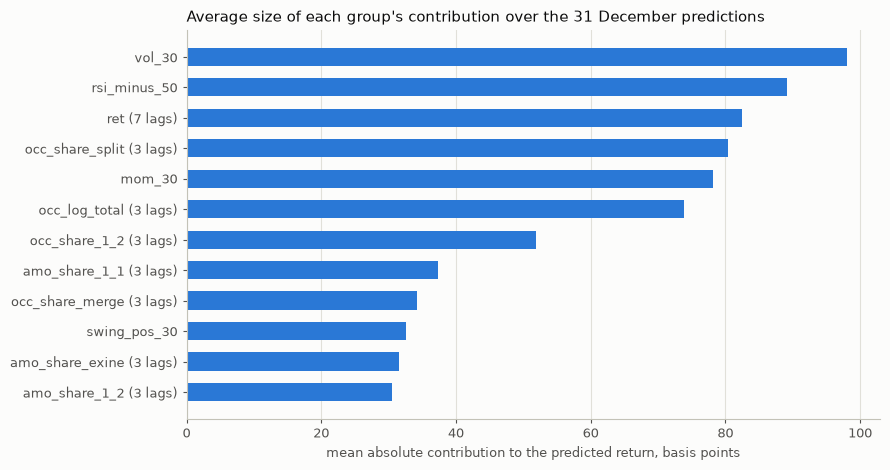

In [31]:
import matplotlib.patheffects as patheffects
from matplotlib.patches import Patch


def style_bars(ax, title, xlabel):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=SECONDARY, labelsize=9, length=3)
    ax.set_xlabel(xlabel, color=SECONDARY, fontsize=9)


shown = group_table.head(12)[::-1]
fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
ax.barh([group_label(g) for g in shown.index], shown["mean |contribution|"], color=BLUE, height=0.6)
style_bars(
    ax,
    "Average size of each group's contribution over the 31 December predictions",
    "mean absolute contribution to the predicted return, basis points",
)
fig.tight_layout()
plt.show()

In [32]:
display(group_table.head(12).round(1))
display(family_table.round(1))
display(extrapolation.to_frame())

,family,mean |contribution|,mean contribution,days pushing up
vol_30,price history,98.0,98.0,31
rsi_minus_50,swing and momentum,89.1,53.0,20
ret,price history,82.4,-29.4,12
occ_share_split,occurrence chainlets,80.5,-80.5,0
mom_30,price history,78.1,-78.1,0
occ_log_total,occurrence chainlets,73.8,71.2,29
occ_share_1_2,occurrence chainlets,51.9,50.2,29
amo_share_1_1,amount chainlets,37.3,-2.5,16
occ_share_merge,occurrence chainlets,34.2,-25.9,6
swing_pos_30,swing and momentum,32.6,18.7,20


,mean |contribution|,mean contribution,days pushing up,share of day-to-day variation (%),"mean |contribution|, frozen model"
price history,105.6,-31.3,12,22.2,145.8
swing and momentum,75.1,28.6,20,3.1,79.1
occurrence chainlets,46.4,13.6,21,18.4,46.0
amount chainlets,71.6,19.9,17,56.4,81.5


,value
"features beyond 2 sd, fewest on a day",3
"features beyond 2 sd, median day",11
"features beyond 2 sd, most on a day",18
share of all December values beyond 2 sd (%),17.2
share expected for a normal distribution (%),4.6


**Reading the month.** Averaged over the 31 days, the largest contributions come from 30-day volatility (98
basis points), RSI (89), the seven daily returns (82), the split share of the occurrence chainlets (80), 30-day
momentum (78) and the log total of occurrences (74). By family, price history averages 106, swing and momentum
75, amount chainlets 72 and occurrence chainlets 46.

A large average is not the same as a varying one. Volatility pushes the prediction up on all 31 days, while
30-day momentum and the occurrence split share push it down on all 31. These standing pushes are the model
reading December itself. On a median day 11 of the 60 features sit more than two standard deviations from their
window average, 17 percent of all values against 4.6 percent for a normal distribution, and a linear model
carries its weights straight through that range. The standing pushes largely cancel: the family means add up to
a net push of only 31 basis points a day.

What changes the prediction from one day to the next is a different question, and the share column of the
family table answers it. The amount chainlets account for 56 percent of the day-to-day variation of the net push
and the occurrence chainlets for 18, so the chainlets together are three quarters of it, against 22 percent for
price history and 3 for swing and momentum. This fits Section 5, where adding the amount chainlets improved the
validation RMSE from 257.7 to 249.4 dollars and adding the occurrence chainlets made it worse. Several
occurrence groups rank high on size, but they are standing pushes of opposite sign, the split share down and the
log total up, so they cancel inside the family and add little variation.

The model frozen on November 30 gives the same picture. The rank correlation of its 26 group importances with
the daily refit is 0.93, and price history is the largest family and occurrence the smallest in both. Swing and
momentum and amount chainlets trade places in the middle.

### Three December days

Three predictions are explained one by one. They are picked by a rule that was fixed before any of their
explanations were looked at, from the errors in Section 6: the day with the largest absolute error, then the
day with the largest absolute predicted return among the rest, which is the model's strongest call, then the
day with the smallest absolute error among the rest. That gives a large miss, a confident call and a close hit.
Each chart starts at the base value and adds the contribution of one feature group per bar, largest first, until
it reaches the model's output. The table under it lists the single features with the largest contributions.

In [33]:
miss = (december_run["predicted"] - december_run["actual"]).abs()
call = december_run["predicted_return"].abs()
largest_miss = miss.idxmax()
strongest_call = call.drop(largest_miss).idxmax()
closest_hit = miss.drop([largest_miss, strongest_call]).idxmin()
chosen = {"largest miss": largest_miss, "strongest call": strongest_call, "closest hit": closest_hit}


def month_day(day):
    return "December %d" % day.day


overview = pd.DataFrame(
    {
        ("price, USD", "previous"): december_run["previous_price"],
        ("price, USD", "actual"): december_run["actual"],
        ("price, USD", "predicted"): december_run["predicted"],
        ("price, USD", "error"): december_run["predicted"] - december_run["actual"],
        ("return, basis points", "actual"): np.log(december_run["actual"] / december_run["previous_price"]) * BP,
        ("return, basis points", "base value"): base_bp,
        **{("return, basis points", family): by_family[family] for family in FAMILIES},
        ("return, basis points", "model output"): output_bp,
    }
).loc[list(chosen.values())]
overview.index = ["%s, %s" % (label, month_day(day)) for label, day in chosen.items()]
overview.round(1)

price, USD                            return, basis points                                              \
                             previous   actual predicted   error               actual base value price history swing and momentum   
largest miss, December 7      13541.0  16502.0   13430.3 -3071.7               1977.6       53.4        -213.1              135.4   
strongest call, December 9    16007.4  15142.8   16557.4  1414.5               -555.3       55.2         -44.3              113.0   
closest hit, December 4       11332.6  11584.8   11564.0   -20.8                220.1       52.0         -20.2               99.6   

                                                                               
                           occurrence chainlets amount chainlets model output  
largest miss, December 7                   30.0            -87.8        -82.1  
strongest call, December 9                 70.5            143.3        337.8  
closest hit, December 4                    19.9             50.8        202.1

In [34]:
def waterfall(day, shown=8):
    """From the base value to the model output, one bar per feature group, largest first."""
    steps = by_group.loc[day]
    order = steps.abs().sort_values(ascending=False).index
    bars = steps[order[:shown]].tolist() + [steps[order[shown:]].sum()]
    labels = [group_label(g) for g in order[:shown]] + ["%d other groups" % (len(order) - shown)]
    starts = base_bp[day] + np.concatenate([[0.0], np.cumsum(bars)[:-1]])
    height = 0.62

    fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
    for position, (step, start) in enumerate(zip(bars, starts)):
        ax.barh(position, step, left=start, height=height, color=BLUE if step > 0 else ORANGE)
        label = ax.annotate(
            "%+.0f" % step,
            xy=(start + step, position),
            xytext=(5 if step > 0 else -5, 0),
            textcoords="offset points",
            ha="left" if step > 0 else "right",
            va="center",
            color=SECONDARY,
            fontsize=9,
        )
        # A surface-colored outline keeps the number readable where it meets the base or output line.
        label.set_path_effects([patheffects.withStroke(linewidth=3, foreground=SURFACE)])
        if position < len(bars) - 1:  # hairline from this bar's end to the start of the next one
            link = [position + height / 2, position + 1 - height / 2]
            ax.plot([start + step] * 2, link, color=AXIS, linewidth=0.8)

    # The two ends of the path are lines across the bars, labeled above and below them so labels cannot collide.
    ends = [
        ("base value", base_bp[day], SECONDARY, -0.6, "bottom"),
        ("model output", output_bp[day], INK, len(bars) - 0.4, "top"),
    ]
    for name, x, color, y, va in ends:
        ax.plot([x, x], [-0.5, len(bars) - 0.5], color=color, linewidth=1, zorder=0)
        ax.text(x, y, "%s %+.0f" % (name, x), ha="center", va=va, color=color, fontsize=9)
    # Zero is in view, so the sign of the output (a predicted rise or fall) can be read off the axis.
    reach = np.concatenate([starts, starts + bars, [base_bp[day], output_bp[day], 0.0]])
    pad = 0.12 * (reach.max() - reach.min())
    ax.set_xlim(reach.min() - pad, reach.max() + pad)
    ax.set_yticks(range(len(bars)), labels)
    ax.set_ylim(len(bars) + 0.1, -1.2)
    title = "%s: from the base value to the model output" % month_day(day)
    style_bars(ax, title, "predicted next-day return, basis points")
    ax.legend(
        handles=[Patch(color=BLUE, label="raises the predicted return"), Patch(color=ORANGE, label="lowers it")],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.14),
        ncol=2,
        frameon=False,
        fontsize=9,
        labelcolor=SECONDARY,
    )
    fig.tight_layout()


def top_features(day, count=8):
    """The single features with the largest contributions on one day, with the numbers behind each."""
    detail = details[day]
    order = detail["contribution"].abs().sort_values(ascending=False).index[:count]
    shown = detail.loc[order].rename(columns={"weight": "weight (bp per sd)", "contribution": "contribution (bp)"})
    shown.insert(0, "family", [FAMILY_OF[name] for name in order])
    return shown.round(
        {"value": 3, "window average": 3, "sd from average": 1, "weight (bp per sd)": 1, "contribution (bp)": 1}
    )

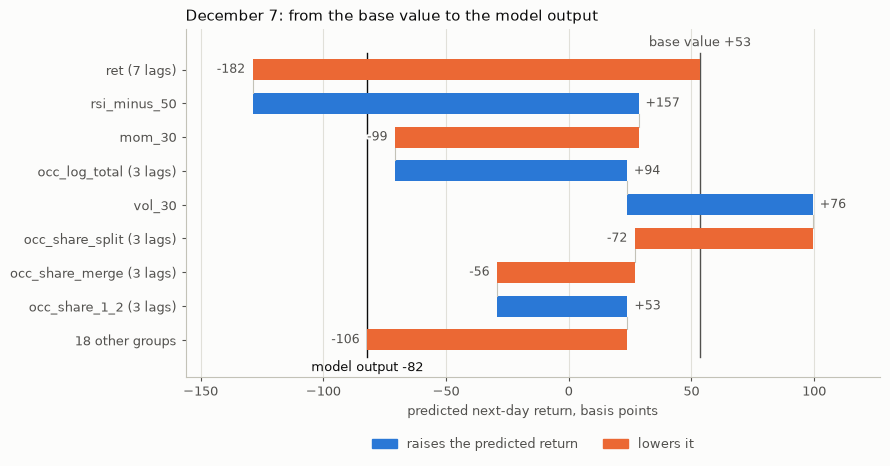

,family,value,window average,sd from average,weight (bp per sd),contribution (bp)
occ_log_total_lag0,occurrence chainlets,12.966,12.390,3.0,58.7,177.0
rsi_minus_50,swing and momentum,40.543,10.063,2.3,68.0,157.2
ret_lag0,price history,0.131,0.005,3.6,-32.3,-116.9
mom_30,price history,0.661,0.134,2.6,-38.1,-99.2
occ_share_merge_lag0,occurrence chainlets,0.092,0.132,-2.6,31.8,-81.5
vol_30,price history,0.052,0.031,1.3,59.8,75.7
occ_share_1_2_lag2,occurrence chainlets,0.665,0.595,1.5,41.5,64.0
amo_share_1_1_lag1,amount chainlets,0.004,0.007,-1.0,54.8,-56.3


In [35]:
waterfall(largest_miss)
plt.show()
top_features(largest_miss)

**December 7, the largest miss.** The model predicted 13,430 dollars, 111 below the previous close of 13,541,
and the price closed at 16,502, up 2,961. The error of 3,072 dollars is the largest of the month. The output of
-82 basis points is the base value of +53 plus a net push of -136 from the features.

The prediction rests on December 6, a day on which the price rose 14 percent. That return was 3.6 standard
deviations above the window average and 30-day momentum was 2.6 above, and the weights on both are negative, so
the model reads the jump as a reason to expect a pullback. The seven return lags subtract 182 basis points and
momentum 99. Two groups push the other way: RSI was 90.5, 2.3 standard deviations above average, and the log
total of occurrence chainlets was 3.0 above, which the model treats as strength. They add 157 and 94. By family,
price history takes off 213, swing and momentum adds 135, and the chainlets net to -58 (occurrence +30, amount
-88).

The eight largest groups nearly cancel, at -30 basis points together, and the 18 smaller ones subtract 106, so
no short list of features explains this output. The model weighed a reversal against strength and expected the
price to give back a little. None of its 60 features signals a rise of 22 percent in a day. The chart says what
the model weighed, not why the price jumped.

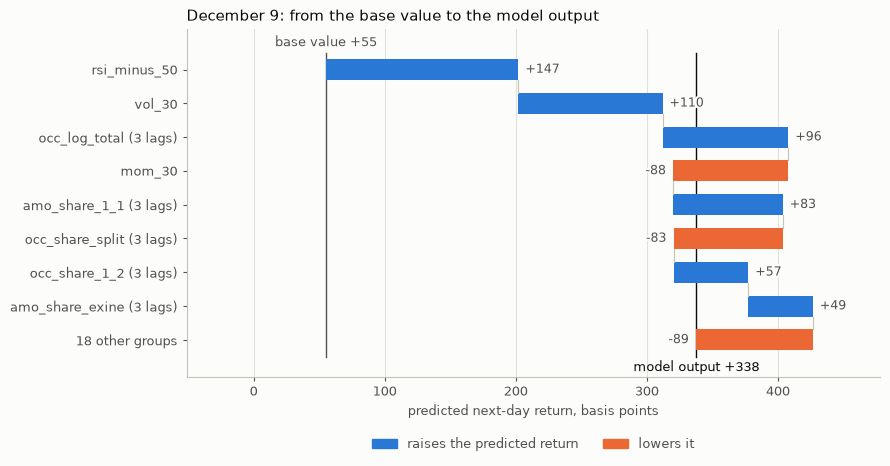

,family,value,window average,sd from average,weight (bp per sd),contribution (bp)
occ_log_total_lag0,occurrence chainlets,12.898,12.392,2.6,60.9,159.7
rsi_minus_50,swing and momentum,38.180,10.128,2.1,69.6,146.8
vol_30,price history,0.062,0.031,1.9,58.7,109.9
occ_share_1_2_lag2,occurrence chainlets,0.701,0.596,2.3,40.3,94.6
amo_share_1_1_lag1,amount chainlets,0.014,0.007,1.8,50.8,89.9
mom_30,price history,0.769,0.136,3.1,-28.5,-87.7
amo_share_exine_lag0,amount chainlets,0.184,0.086,1.9,34.4,66.8
occ_share_merge_lag0,occurrence chainlets,0.098,0.132,-2.1,24.5,-51.9


In [36]:
waterfall(strongest_call)
plt.show()
top_features(strongest_call)

**December 9, the strongest call.** The model predicted 16,557 dollars, 550 above the previous close of 16,007,
an output of +338 basis points, the largest of the month in absolute size. The price fell to 15,143, so the
error is 1,415 dollars with the prediction too high.

Everything the model rewards was high at once. RSI was 88.2, 2.1 standard deviations above average, and adds 147
basis points. 30-day volatility, 1.9 above average, adds 110, and the log total of occurrences, 2.6 above, adds
96. The chainlet families supply 214 of the 283 basis points of net push (amount +143, occurrence +71), against
+113 from swing and momentum and -44 from price history. Without the chainlet families the push would be +69 and
the output +124, so the chainlets are what turn a positive call into the strongest one of the month.

The fitted weights on RSI, volatility and the current activity level are positive: in the 730-day window, with
the other features held fixed, higher readings went with higher next-day returns. The model has no feature that
separates a strong market from an overextended one, so readings that went with gains in the window produced a
call for a rise on a day when the price fell 5 percent.

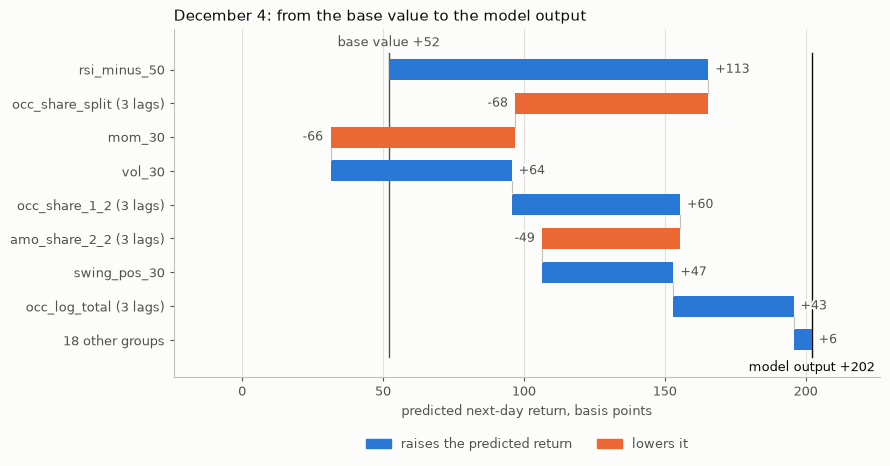

,family,value,window average,sd from average,weight (bp per sd),contribution (bp)
rsi_minus_50,swing and momentum,34.375,9.965,1.9,60.8,113.5
occ_log_total_lag0,occurrence chainlets,12.783,12.386,2.1,54.0,113.4
mom_30,price history,0.454,0.132,1.6,-41.1,-65.6
occ_share_1_2_lag2,occurrence chainlets,0.665,0.594,1.6,41.4,64.6
vol_30,price history,0.049,0.031,1.1,56.7,64.3
amo_share_exine_lag0,amount chainlets,0.154,0.085,1.4,38.9,53.7
swing_pos_30,swing and momentum,1.000,0.699,1.0,45.1,46.5
occ_share_split_lag1,occurrence chainlets,0.730,0.658,2.0,-21.9,-44.7


In [37]:
waterfall(closest_hit)
plt.show()
top_features(closest_hit)

**December 4, the closest hit.** The model predicted 11,564 dollars against an actual close of 11,585, an error
of 21 dollars. From the previous close of 11,333 it called a rise of 231 dollars (+202 basis points), and the
price rose 252 (+220).

Swing and momentum supply most of the push, +100 of +150 basis points. RSI was 84.4, 1.9 standard deviations
above average, and adds 113, and the price closed at the top of its 30-day range, which adds 47. Volatility adds
64, the 1:2 share of occurrences 60 and the log total of occurrences 43. 30-day momentum (-66) and the occurrence
split share (-68) pull back. By family, the chainlets add +71 and price history -20.

These are the same groups pushing in the same directions as on December 9, only less strongly (RSI +113 against
+147, volatility +64 against +110). Here the price rose about as much as predicted, and five days later it fell
when the model predicted a rise. One close hit does not show that the model reads the market correctly: over
the month it calls the direction on 12 of 31 days.

### Findings

* The explanations are exact. For all 31 December fits the SHAP values equal the weight times the standardized
  value, the contributions add up to the model's output, the base value is the window's average return and
  equals the drift baseline's prediction, and the rebuilt prices match Section 6 to the cent.
* The output is a base value of about +54 basis points a day plus contributions of both signs, and a single
  feature can move it by well over 100. The net push of the features was -136, +283 and +150 on the three days
  explained.
* Much of the explanation is a standing push. Volatility pushes up on every day, and 30-day momentum and the
  occurrence split share push down on every day. December inputs sit far from the fit window, with 17 percent
  of values beyond two standard deviations, so the contributions are largely the model's linear extrapolation of
  December itself.
* The day-to-day variation of the net push comes mostly from the chainlets: 56 percent from the amount
  chainlets and 18 from the occurrence chainlets, against 22 from price history and 3 from swing and momentum.
  This matches Section 5, where the amount chainlets were the family that helped the validation score most.
  Leaning on a family is not the same as being right, and December did not reward it.
* The three days show how the model fails. On December 7 a reversal reading after a 14 percent day outweighed
  strength, and the model predicted a fall before a 22 percent rise. On December 9 high RSI, volatility and
  activity, with the chainlets adding most of the push, gave the strongest call of the month on a day the price
  fell 5 percent. On December 4 the same pattern gave a close hit. The model cannot tell these situations apart.
* SHAP describes the model, not the market. A positive contribution means the fitted weight pushes the predicted
  return up, not that the feature moves the price, and the weights come from a 730-day window that ended before
  December.

## 8. Predictions file

## 9. Compliance audit